<a href="https://colab.research.google.com/github/bforoura/ML26/blob/main/Module9a_NN/breast_cancer_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to Artificial Neural Networks with Keras**

* The notebook covers the following topics:
  1. **The Biological Inspiration & Single Perceptrons:** Understanding artificial neurons, weighted inputs, bias, and decision boundaries.

  2. **Activation Functions:** Exploring why non-linearities such as **ReLU** and **Sigmoid** are essential for learning complex patterns.

  3. **Multilayer Perceptrons (MLPs):** Building, compiling, and training feedforward neural networks.

  4. **Training & Optimization:** Monitoring loss and accuracy curves, managing epochs, and configuring learning rates and optimizers.

  5. **Medical Diagnostic Classification:** Applying a classification MLP to    the **Breast Cancer Wisconsin (Diagnostic) Dataset** we used in a previous lecture.

     * Binary classification predicting whether a tumor is malignant or benign.
     * 30 numeric, real-valued input features computed from digitized images of breast masses, e.g., radius, texture, perimeter, area, smoothness, compactness, etc.


## **Step 1: Importing Libraries and Loading the Dataset**

* First set up the environment by importing the needed libraries for data manipulation, neural network construction, and evaluation.

* Then load the Breast Cancer Wisconsin dataset directly from Scikit-Learn, inspect its structure, and prepare the features and target labels for the  neural network model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import the Breast Cancer dataset from sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import TensorFlow and Keras components
import tensorflow as tf
from tensorflow import keras

# Load the dataset
cancer_data = load_breast_cancer()

# Explore the dataset structure
print("Feature Names:", cancer_data.feature_names[:5])
print("Target Classes:", cancer_data.target_names)
print("Data Shape:", cancer_data.data.shape)

# Define feature matrix X and target vector y
X = cancer_data.data
y = cancer_data.target

# Split the data into training (80%) and validation/test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features to have zero mean and unit variance, which is crucial for neural network training
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape after scaling:", X_train_scaled.shape)
print("Test set shape after scaling:", X_test_scaled.shape)

Feature Names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Target Classes: ['malignant' 'benign']
Data Shape: (569, 30)
Training set shape after scaling: (455, 30)
Test set shape after scaling: (114, 30)


## **Step 2: Building the Classification MLP Model**

* In this section, we construct a Multilayer Perceptron (MLP) for binary classification using the Keras Sequential API.

* Our architecture consists of:
  1. An **input** layer corresponding to our 30 scaled features.
  2. Two** hidden layers** using the **Rectified Linear Unit (ReLU)** activation function to learn **non-linear patterns**.
  3. A **single output** neuron with a **sigmoid** activation function, which outputs a value between 0 and 1 representing the **estimated probability of the positive class**.

In [2]:
# Build the classification MLP model using the Sequential API
model = keras.models.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(30, activation="relu"),
    keras.layers.Dense(15, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# Display the model summary to review architecture and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           465 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,411 (5.51 KB)

 Trainable params: 1,411 (5.51 KB)

 Non-trainable params: 0 (0.00 B)

## **Visualizing the Neural Network Architecture**

* Let's define a custom plotting function to dynamically draw our specific neural network architecture (`30 -> 30 -> 15 -> 1`).

* The function renders individual neurons, connecting edges, layer titles, and  descriptive labels.

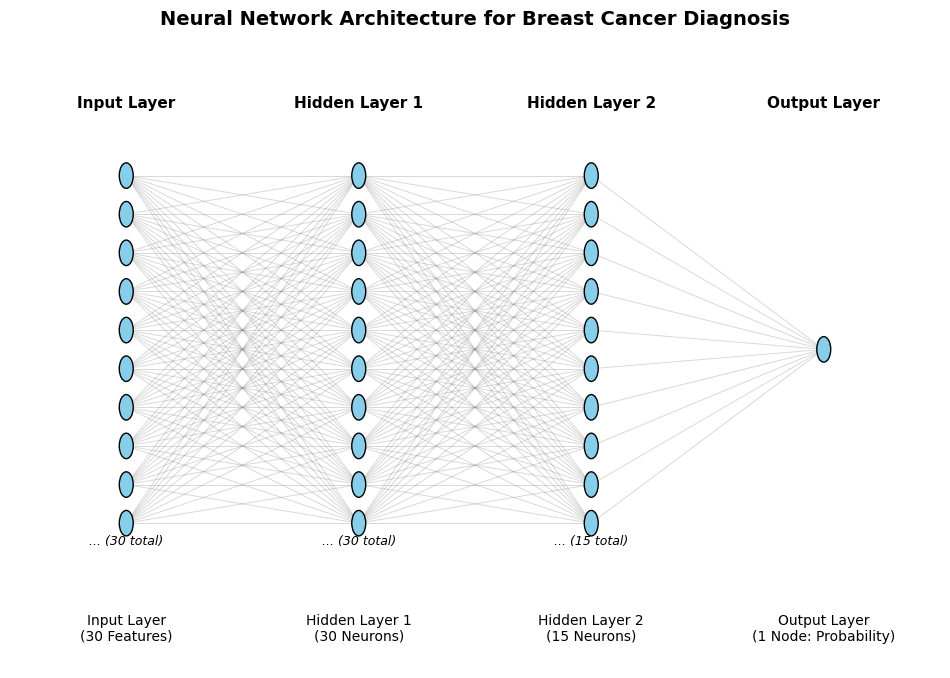

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def draw_neural_network(layer_sizes, layer_names=None):
    """
    Draws a clean neural network diagram showing individual neurons, edges,
    proper top titles, and clearly positioned bottom descriptions without clipping.
    """
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis('off')

    # Set axis limits with ample padding to prevent clipping at the top and bottom
    ax.set_ylim(-0.25, 1.2)
    ax.set_xlim(0.5, len(layer_sizes) + 0.5)

    # Draw connections (edges)
    for i, layer_size in enumerate(layer_sizes[:-1]):
        current_x = (i + 1)
        next_x = (i + 2)

        display_curr = min(layer_size, 10)
        display_next = min(layer_sizes[i + 1], 10)

        for j in range(display_curr):
            current_y = 1.0 - (j + 1) * (1.0 / (display_curr + 1))
            for k in range(display_next):
                next_y = 1.0 - (k + 1) * (1.0 / (display_next + 1))

                line = plt.Line2D([current_x, next_x], [current_y, next_y], c='gray', alpha=0.3, linewidth=0.7)
                ax.add_line(line)

    # Draw individual neurons and labels
    for i, layer_size in enumerate(layer_sizes):
        current_x = (i + 1)
        display_count = min(layer_size, 10)

        for j in range(display_count):
            current_y = 1.0 - (j + 1) * (1.0 / (display_count + 1))

            circle = plt.Circle((current_x, current_y), 0.03, color='skyblue', ec='black', zorder=4)
            ax.add_patch(circle)

        # Display ellipsis if layer has more than 10 nodes
        if layer_size > display_count:
            ax.text(current_x, 0.05, f"... ({layer_size} total)", fontsize=9, ha='center', va='center', style='italic', color='black')

        # Layer Titles at the Top
        if layer_names and i < len(layer_names):
            ax.text(current_x, 1.08, layer_names[i], fontsize=11, fontweight='bold', ha='center', va='center')

        # Descriptive Labels at the Bottom
        if i == 0:
            desc = f"Input Layer\n({layer_size} Features)"
        elif i == len(layer_sizes) - 1:
            desc = f"Output Layer\n({layer_size} Node: Probability)"
        else:
            desc = f"Hidden Layer {i}\n({layer_size} Neurons)"

        ax.text(current_x, -0.12, desc, fontsize=10, ha='center', va='top', color='black')

    plt.title("Neural Network Architecture for Breast Cancer Diagnosis", fontsize=14, fontweight='bold', pad=20)
    plt.show()

# Actual layer sizes for our model: 30 inputs -> 30 hidden -> 15 hidden -> 1 output
actual_layer_sizes = [30, 30, 15, 1]
layer_labels = ["Input Layer", "Hidden Layer 1", "Hidden Layer 2", "Output Layer"]
draw_neural_network(actual_layer_sizes, layer_labels)

## **Step 3: Compiling and Training the Model**

* Now, compile the model by specifying the loss function, optimizer, and evaluation metrics.

* Because our task is binary classification using a sigmoid output layer, we use **binary cross-entropy loss**.

* We then train the model using `model.fit()` over **30 epochs** and capture the training history to visualize our loss and validation accuracy curves.

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7363 - loss: 0.6463 - val_accuracy: 0.8242 - val_loss: 0.5856
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9011 - loss: 0.5526 - val_accuracy: 0.8901 - val_loss: 0.5085
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9313 - loss: 0.4790 - val_accuracy: 0.9121 - val_loss: 0.4413
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9368 - loss: 0.4067 - val_accuracy: 0.9121 - val_loss: 0.3766
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9505 - loss: 0.3369 - val_accuracy: 0.9231 - val_loss: 0.3155
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9588 - loss: 0.2745 - val_accuracy: 0.9231 - val_loss: 0.2632
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9643 - loss: 0.2224 - val_accuracy: 0.9341 - val_loss: 0.2237
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9670 - loss: 0.1819 - val_accuracy: 0.9341 - val_los

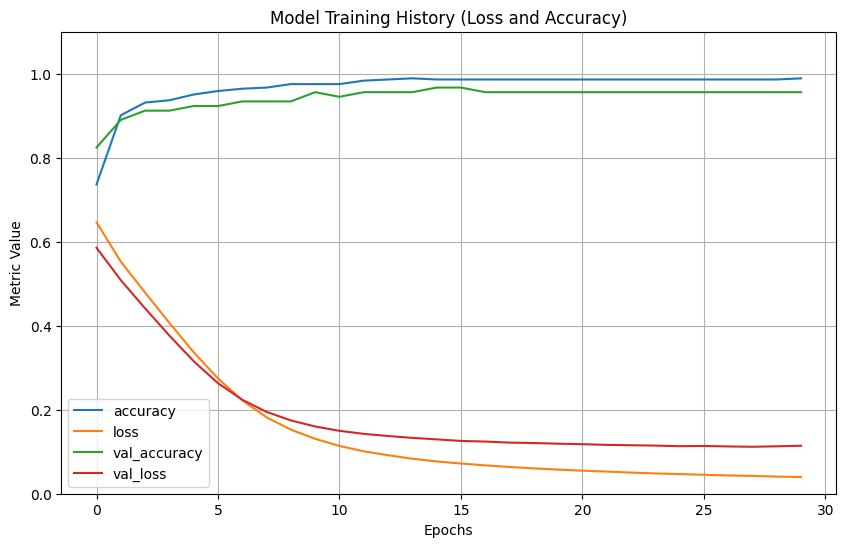

In [7]:
# Compile the model
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Train the model
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    validation_split=0.2,
    verbose=1
)

# Plot learning curves for loss and accuracy
pd.DataFrame(history.history).plot(figsize=(10, 6))
plt.grid(True)
plt.gca().set_ylim(0, 1.1)
plt.title("Model Training History (Loss and Accuracy)")
plt.xlabel("Epochs")
plt.ylabel("Metric Value")
plt.show()

## **The Training History Curves**

*  Both curves decrease as the epochs progress, indicating that the network is successfully learning the underlying patterns and minimizing the binary cross-entropy error.

* Both metrics rise quickly in the first few epochs and level off at a high performance level exceeding 95% accuracy.

* Notice how the validation curves track the training curves without a big gap. This indicates that the model is **generalizing well to unseen data and avoiding overfitting.**

## **Step 4: Evaluating the Model and Making Predictions**

* Ealuate the trained neural network on the unseen test dataset using `model.evaluate()` to check its generalization performance.


* Use`model.predict()` to generate probability estimates on new instances and threshold them to obtain final class predictions.

In [8]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Make predictions on new test instances
X_new = X_test_scaled[:5] # Take the first 5 test samples
y_pred_probs = model.predict(X_new)
y_pred_classes = (y_pred_probs > 0.5).astype("int32")

# Display prediction results alongside actual labels
print("\nPredictions on 5 new samples:")
for i in range(5):
    print(f"Sample {i+1}: Predicted Probability = {y_pred_probs[i][0]:.4f} | Predicted Class = {y_pred_classes[i][0]} | Actual Class = {y_test[i]}")

Test Loss: 0.0770
Test Accuracy: 96.49%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step

Predictions on 5 new samples:
Sample 1: Predicted Probability = 0.9272 | Predicted Class = 1 | Actual Class = 1
Sample 2: Predicted Probability = 0.0002 | Predicted Class = 0 | Actual Class = 0
Sample 3: Predicted Probability = 0.0036 | Predicted Class = 0 | Actual Class = 0
Sample 4: Predicted Probability = 0.9966 | Predicted Class = 1 | Actual Class = 1
Sample 5: Predicted Probability = 0.9996 | Predicted Class = 1 | Actual Class = 1


## **Visualizing Test Results and Prediction Probabilities**


* Evaluate the trained model on the complete test dataset to obtain overall performance metrics.

* Let's select **10 sample test cases**  to graphically plot their predicted probabilities against the 0.5 decision threshold, allowing us to inspect individual model confidence and compare predictions directly with actual classes.

Test Loss: 0.0770
Test Accuracy: 96.49%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step


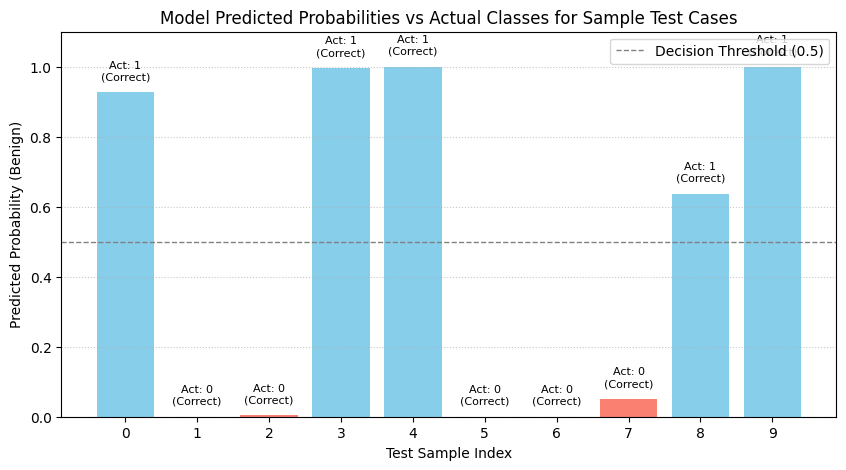

In [9]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Make predictions on new test instances
X_new = X_test_scaled[:10] # Take the first 10 test samples for better visualization
y_pred_probs = model.predict(X_new).flatten()
y_pred_classes = (y_pred_probs > 0.5).astype("int32")
y_actual = y_test[:10]

# Graphically plot the predicted probabilities vs actual classes
plt.figure(figsize=(10, 5))
bars = plt.bar(range(len(y_pred_probs)), y_pred_probs, color=['skyblue' if p > 0.5 else 'salmon' for p in y_pred_probs])
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Decision Threshold (0.5)')

plt.xlabel('Test Sample Index')
plt.ylabel('Predicted Probability (Benign)')
plt.title('Model Predicted Probabilities vs Actual Classes for Sample Test Cases')
plt.xticks(range(len(y_pred_probs)))
plt.ylim(0, 1.1)

# Annotate actual vs predicted labels on the plot
for i, bar in enumerate(bars):
    yval = bar.get_height()
    status = "Correct" if y_pred_classes[i] == y_actual[i] else "Incorrect"
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"Act: {y_actual[i]}\n({status})", ha='center', va='bottom', fontsize=8)

plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

## **The Prediction Probability Plot**

The attached plot visualizes the model's performance across 10 sample test cases (indexed 0 through 9):

*  The horizontal dashed line at $0.5$ separates the two classes.
   * Bars extending above $0.5$ are classified as <font color=blue>**positive** (**benign**</font>)
   * Bars falling below $0.5$ are classified as <font color=red>**negative** (**malignant, represented in red**</font>).

  * <font color=blue>**Tall bars**</font> near $1.0$ (such as samples 0, 3, 4, and 9) indicate that the model is **highly confident** the tumor is **benign**.
  
  * **Low bars** near $0.0$ (such as samples 1, 2, 5, 6, and 7) show **high confidence** that the tumor is **malignant**.



## **Step 5: Saving and Loading the Trained Model**

* Once a neural network model is trained and validated, it is standard practice to save the model architecture, weights, and configuration to disk so it can be deployed or reloaded later without requiring retraining.

* In Keras, we can save our trained model to a file and easily reload it to make new predictions.

In [10]:
# Save the trained model to disk in the native Keras format
model.save("breast_cancer_mlp_model.keras")
print("Model successfully saved to disk.")

# Reload the model from disk to verify persistence
reloaded_model = tf.keras.models.load_model("breast_cancer_mlp_model.keras")

# Test the reloaded model on a single test sample
sample_pred = reloaded_model.predict(X_test_scaled[:1])
print(f"Reloaded model prediction probability: {sample_pred[0][0]:.4f}")

Model successfully saved to disk.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
Reloaded model prediction probability: 0.9272


## **Step 6: Detailed Performance Evaluation (Confusion Matrix and Classification Report)**

* While overall test accuracy gives us a high-level performance metric, it can sometimes obscure critical details, especially in medical diagnostics where the cost of a **false negative** is extremely high.

* Let's generate full test set predictions and compute a **Confusion Matrix** alongside a **Classification Report** to analyze precision, recall, and F1-score across both classes.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step 
Confusion Matrix:
[[41  2]
 [ 2 69]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        43
      benign       0.97      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



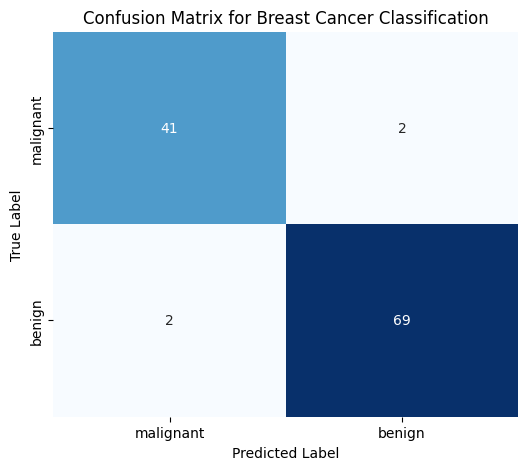

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Generate class predictions for the entire test set
y_test_pred_probs = model.predict(X_test_scaled).flatten()
y_test_pred_classes = (y_test_pred_probs > 0.5).astype("int32")

# Compute confusion matrix
conf_matrix = confusion_matrix(y_test, y_test_pred_classes)
print("Confusion Matrix:")
print(conf_matrix)

# Print detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_classes, target_names=cancer_data.target_names))

# Plot confusion matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=cancer_data.target_names,
            yticklabels=cancer_data.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Breast Cancer Classification')
plt.show()

## **Step 7: Improving Generalization with Dropout Regularization**

* As neural networks grow deeper or more complex, they run the risk of **overfitting—memorizing** the training data rather than learning general underlying patterns.

*  One standard technique to prevent this is **Dropout**, which randomly deactivates a fraction of neurons during each training step.

* This prevents units from co-adapting too much and forces the network to learn more robust features.

* We can define an updated model incorporating **Dropout layers** and observe how it affects our training dynamics and validation performance.

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5659 - loss: 0.6661 - val_accuracy: 0.7582 - val_loss: 0.5149
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7555 - loss: 0.5284 - val_accuracy: 0.8681 - val_loss: 0.4343
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8214 - loss: 0.4625 - val_accuracy: 0.9451 - val_loss: 0.3654
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9231 - loss: 0.3813 - val_accuracy: 0.9670 - val_loss: 0.3069
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9231 - loss: 0.3291 - val_accuracy: 0.9560 - val_loss: 0.2572
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9313 - loss: 0.2718 - val_accuracy: 0.9670 - val_loss: 0.2179
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9396 - loss: 0.2405 - val_accuracy: 0.9670 - val_loss: 0.1876
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9533 - loss: 0.2073 - val_accuracy: 0.9560 - val_loss: 0.165

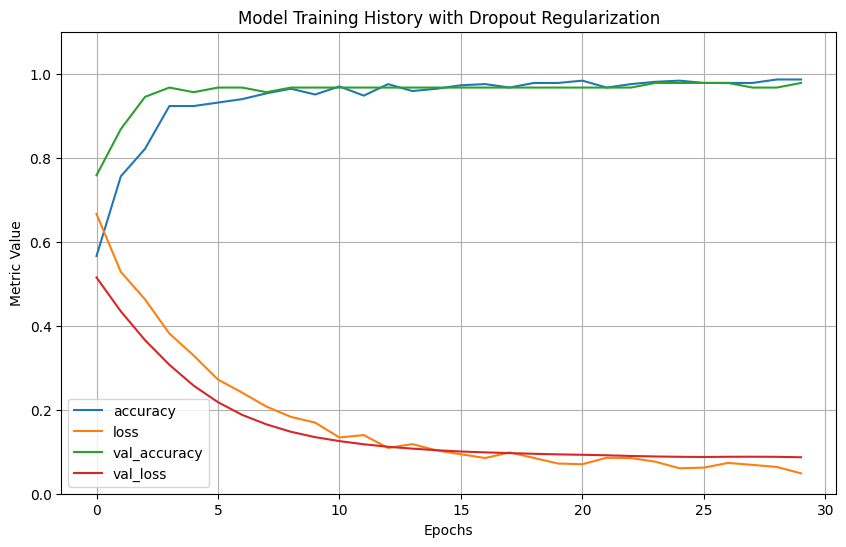

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Define an updated model with Dropout regularization
dropout_model = Sequential([
    Dense(30, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3), # Randomly drop 30% of units during training
    Dense(15, activation='relu'),
    Dropout(0.2), # Randomly drop 20% of units during training
    Dense(1, activation='sigmoid')
])

# Compile the dropout model
dropout_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Train the dropout model over 30 epochs
history_dropout = dropout_model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    validation_split=0.2,
    verbose=1
)

# Plot training history with dropout curves
pd.DataFrame(history_dropout.history).plot(figsize=(10, 6))
plt.grid(True)
plt.gca().set_ylim(0, 1.1)
plt.title("Model Training History with Dropout Regularization")
plt.xlabel("Epochs")
plt.ylabel("Metric Value")
plt.show()

## **Step 8: Comparing the Baseline Model vs. the Dropout Regularized Model**

* To understand the impact of regularization, we evaluate both our original baseline model and the new dropout-regularized model on the same test dataset.

* Comparing their test loss and test accuracy side-by-side lets us determine if the added dropout layers improved generalization without sacrificing predictive performance.

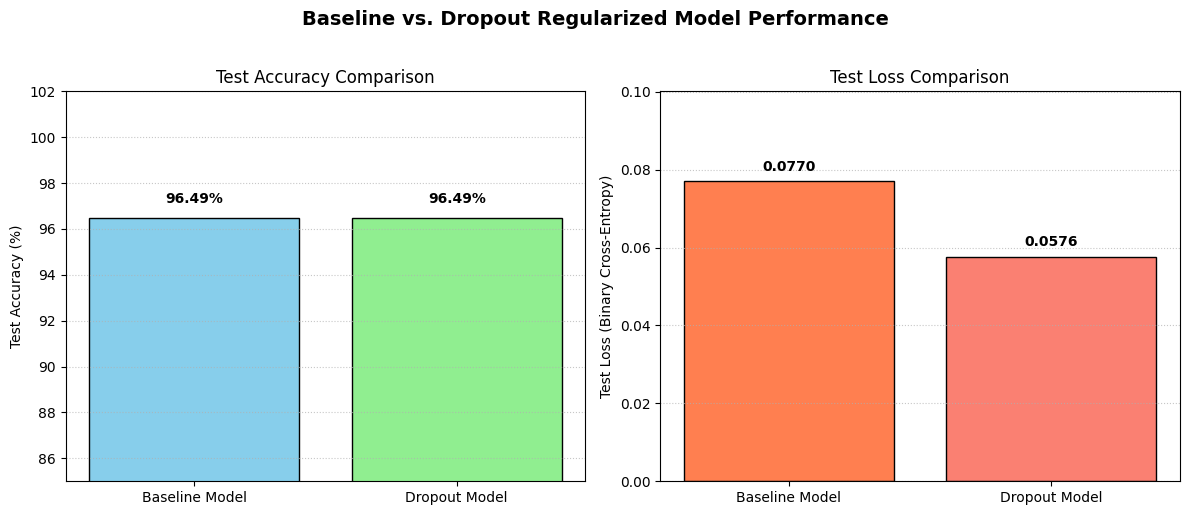

In [14]:
# Create a dual-subplot visualization for Accuracy and Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot Test Accuracy (%)
models = ['Baseline Model', 'Dropout Model']
accuracies = [base_acc * 100, drop_acc * 100]
bars1 = ax1.bar(models, accuracies, color=['skyblue', 'lightgreen'], edgecolor='black')
ax1.set_ylabel('Test Accuracy (%)')
ax1.set_title('Test Accuracy Comparison')
ax1.set_ylim(85, 102)
ax1.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

# Plot Test Loss
losses = [base_loss, drop_loss]
bars2 = ax2.bar(models, losses, color=['coral', 'salmon'], edgecolor='black')
ax2.set_ylabel('Test Loss (Binary Cross-Entropy)')
ax2.set_title('Test Loss Comparison')
ax2.set_ylim(0, max(losses) * 1.3)
ax2.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle("Baseline vs. Dropout Regularized Model Performance", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## **Explaining the Baseline vs. Dropout Model Comparison Output**

* Both models achieve a test accuracy of **96.49%**, represented by identical bar heights on the plot.

* This indicates that adding dropout regularization did not sacrifice the overall predictive accuracy of the model on the unseen test set.

* Although the accuracy is the same, the **Dropout Model** achieves a lower test loss ($0.0576$) compared to the **Baseline Model** ($0.0770$).

* A lower loss value means the regularized model makes its correct predictions with higher confidence and lower overall penalty error, reflecting better generalization and robustness.

## **Step 10: Using Early Stopping Callbacks**

* When training neural networks, **choosing the exact number of epochs can be challenging. **

* Training for too few epochs leads to **underfitting**, while training for too many can lead to **overfitting and wasted computational time**.

* To solve this, we can use **Callbacks** such as **EarlyStopping**.

* This added feature will monitor the validation loss during training and automatically halt the process when performance stops improving, restoring the optimal model weights.

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

# Define an EarlyStopping callback to monitor validation loss
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,          # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True
)

# Create a new model instance for early stopping demonstration
callback_model = Sequential([
    Dense(30, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(15, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

callback_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Train the model with the early stopping callback enabled
history_callback = callback_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,                  # Set a higher max epoch limit
    validation_split=0.2,
    callbacks=[early_stopping], # Pass the callback here
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7225 - loss: 0.5559 - val_accuracy: 0.8791 - val_loss: 0.4120
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8599 - loss: 0.4115 - val_accuracy: 0.9231 - val_loss: 0.3124
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8709 - loss: 0.3564 - val_accuracy: 0.9341 - val_loss: 0.2540
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9121 - loss: 0.2605 - val_accuracy: 0.9341 - val_loss: 0.2182
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9066 - loss: 0.2434 - val_accuracy: 0.9451 - val_loss: 0.1935
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9176 - loss: 0.2197 - val_accuracy: 0.9451 - val_loss: 0.1760
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9286 - loss: 0.1962 - val_accuracy: 0.9451 - val_loss: 0.1632
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9368 - loss: 0.1828 - val_accuracy: 0.9560 - val_loss: 0.1536


## **Step 11: Comprehensive Comparison of All Three Models**

* Now that we have trained our baseline model, our dropout-regularized model, and our early-stopping callback model, we can perform a final comprehensive comparison.

* In this section, we evaluate the early stopping model on the test set and plot all three models side-by-side across both **Test Accuracy** and **Test Loss**.

Comprehensive Model Comparison Summary:
-------------------------------------------------------
1. Baseline Model         -> Test Loss: 0.0770 | Test Accuracy: 96.49%
2. Dropout Model          -> Test Loss: 0.0576 | Test Accuracy: 96.49%
3. Early Stopping Model   -> Test Loss: 0.0642 | Test Accuracy: 97.37%


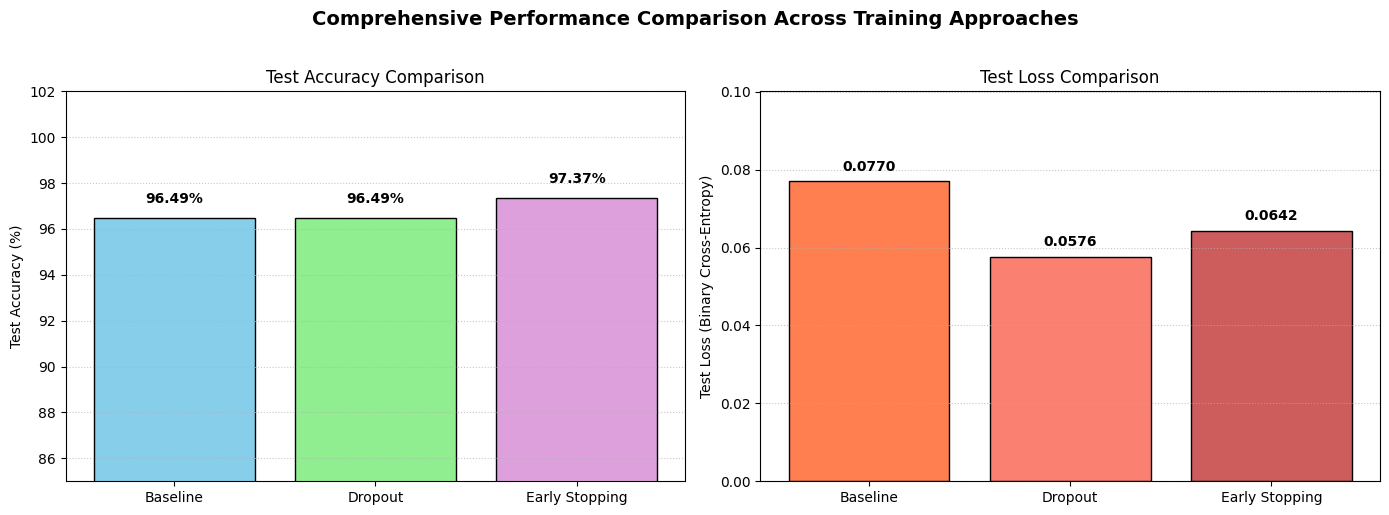

In [16]:
# Evaluate early stopping model on the test set
cb_loss, cb_acc = callback_model.evaluate(X_test_scaled, y_test, verbose=0)

# Print and compare performance metrics across all three models
print("Comprehensive Model Comparison Summary:")
print("-" * 55)
print(f"1. Baseline Model         -> Test Loss: {base_loss:.4f} | Test Accuracy: {base_acc * 100:.2f}%")
print(f"2. Dropout Model          -> Test Loss: {drop_loss:.4f} | Test Accuracy: {drop_acc * 100:.2f}%")
print(f"3. Early Stopping Model   -> Test Loss: {cb_loss:.4f} | Test Accuracy: {cb_acc * 100:.2f}%")

# Create a dual-subplot visualization for Accuracy and Loss across all three models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

models = ['Baseline', 'Dropout', 'Early Stopping']
accuracies = [base_acc * 100, drop_acc * 100, cb_acc * 100]
losses = [base_loss, drop_loss, cb_loss]

# Plot Test Accuracy (%)
bars1 = ax1.bar(models, accuracies, color=['skyblue', 'lightgreen', 'plum'], edgecolor='black')
ax1.set_ylabel('Test Accuracy (%)')
ax1.set_title('Test Accuracy Comparison')
ax1.set_ylim(85, 102)
ax1.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

# Plot Test Loss
bars2 = ax2.bar(models, losses, color=['coral', 'salmon', 'indianred'], edgecolor='black')
ax2.set_ylabel('Test Loss (Binary Cross-Entropy)')
ax2.set_title('Test Loss Comparison')
ax2.set_ylim(0, max(losses) * 1.3)
ax2.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle("Comprehensive Performance Comparison Across Training Approaches", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## **Explaining the Comprehensive Performance Comparison Output**

* Both the **Baseline** and **Dropout** models achieve identical test accuracy at **96.49%**.
  
* The **Early Stopping** model achieves the highest overall test accuracy at **97.37%**. Halting training at the optimal validation epoch prevents unnecessary updates that could degrade performance on unseen data.

* The **Baseline** model shows the highest binary cross-entropy loss (**0.0770**), indicating greater uncertainty or overconfident errors on certain test instances.
  
* Adding **Dropout** significantly reduces test loss to **0.0576**, confirming that random feature dropout acts as an effective regularizer.

* The **Early Stopping** model yields a test loss of **0.0642**, effectively balancing low error loss with superior class accuracy.


---

* While all three approaches perform exceptionally well on this dataset, combining regularization techniques (Dropout) with dynamic training controls (Early Stopping) leads to the best overall generalization performance.

## **Step 12: Accelerating Training with Batch Normalization**

* As neural networks grow deeper, the distribution of inputs to internal layers can shift continuously during training—a phenomenon known as **internal covariate shift**.

* This instability forces lower learning rates and makes training more sensitive to initialization.

**Batch Normalization** addresses this by normalizing the activations of each layer across the mini-batch (**re-centering and re-scaling**).

* This stabilizes the learning process, accelerates convergence, and provides a mild regularizing effect.

* Let's add **Batch Normalization layers** to our neural network architecture and evaluate their impact on performance.

In [17]:
from tensorflow.keras.layers import BatchNormalization

# Define an updated model incorporating Batch Normalization layers
bn_model = Sequential([
    Dense(30, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(15, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile the batch normalization model
bn_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Train the batch normalization model
history_bn = bn_model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    validation_split=0.2,
    verbose=1
)

# Evaluate the batch normalization model on the test set
bn_loss, bn_acc = bn_model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Batch Normalization Model -> Test Loss: {bn_loss:.4f} | Test Accuracy: {bn_acc * 100:.2f}%")

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4176 - loss: 1.1714 - val_accuracy: 0.6264 - val_loss: 0.8167
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5027 - loss: 0.9143 - val_accuracy: 0.7033 - val_loss: 0.5867
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6264 - loss: 0.6813 - val_accuracy: 0.8132 - val_loss: 0.4401
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7308 - loss: 0.5330 - val_accuracy: 0.8681 - val_loss: 0.3512
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7967 - loss: 0.4333 - val_accuracy: 0.8791 - val_loss: 0.3014
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8022 - loss: 0.4223 - val_accuracy: 0.9011 - val_loss: 0.2720
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8599 - loss: 0.3420 - val_accuracy: 0.9011 - val_loss: 0.2506
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8709 - loss: 0.3178 - val_accuracy: 0.9011 - val_los

## **Step 13: Grand Comparison Across All Four Models**

* We have explored four distinct configurations: our standard baseline multi-layer perceptron, the dropout-regularized model, the early-stopping callback model, and the batch-normalized architecture.

* Let's assemble all four models into a unified final comparison, evaluating their test accuracy and test loss side-by-side to review how each architectural enhancement contributes to overall performance.

Grand Model Comparison Summary:
-----------------------------------------------------------------
1. Baseline Model         -> Test Loss: 0.0770 | Test Accuracy: 96.49%
2. Dropout Model          -> Test Loss: 0.0576 | Test Accuracy: 96.49%
3. Early Stopping Model   -> Test Loss: 0.0642 | Test Accuracy: 97.37%
4. Batch Norm Model       -> Test Loss: 0.0989 | Test Accuracy: 94.74%


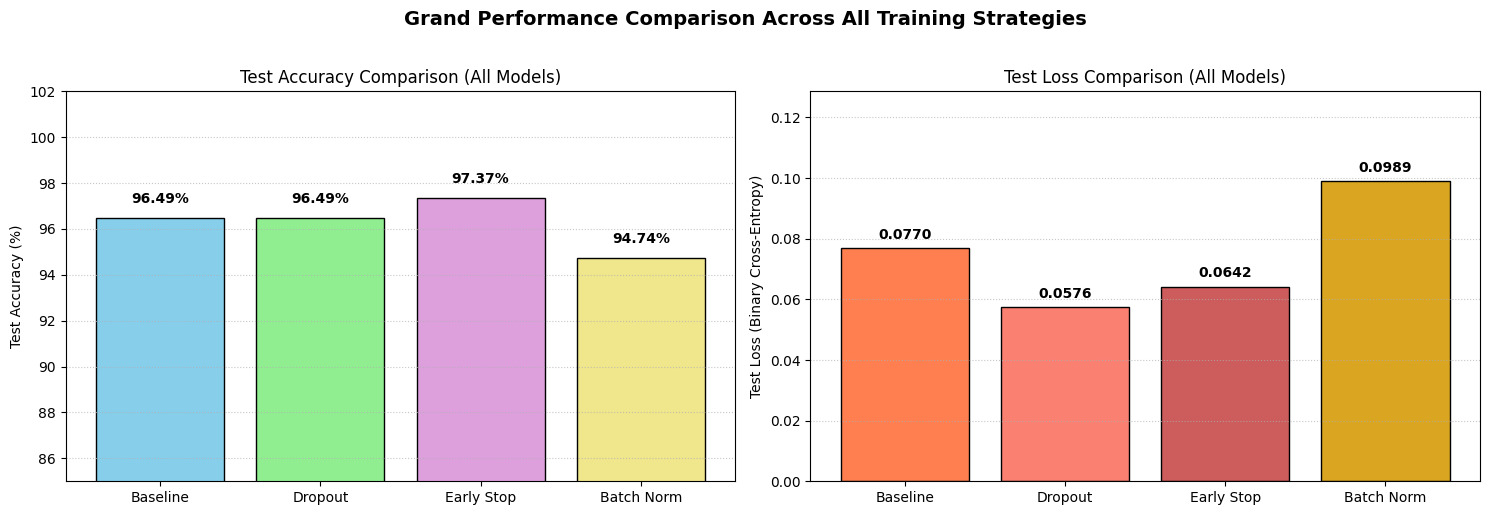

In [18]:
# Print and compare performance metrics across all four models
print("Grand Model Comparison Summary:")
print("-" * 65)
print(f"1. Baseline Model         -> Test Loss: {base_loss:.4f} | Test Accuracy: {base_acc * 100:.2f}%")
print(f"2. Dropout Model          -> Test Loss: {drop_loss:.4f} | Test Accuracy: {drop_acc * 100:.2f}%")
print(f"3. Early Stopping Model   -> Test Loss: {cb_loss:.4f} | Test Accuracy: {cb_acc * 100:.2f}%")
print(f"4. Batch Norm Model       -> Test Loss: {bn_loss:.4f} | Test Accuracy: {bn_acc * 100:.2f}%")

# Create a dual-subplot visualization for Accuracy and Loss across all four models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

models = ['Baseline', 'Dropout', 'Early Stop', 'Batch Norm']
accuracies = [base_acc * 100, drop_acc * 100, cb_acc * 100, bn_acc * 100]
losses = [base_loss, drop_loss, cb_loss, bn_loss]

# Plot Test Accuracy (%)
bars1 = ax1.bar(models, accuracies, color=['skyblue', 'lightgreen', 'plum', 'khaki'], edgecolor='black')
ax1.set_ylabel('Test Accuracy (%)')
ax1.set_title('Test Accuracy Comparison (All Models)')
ax1.set_ylim(85, 102)
ax1.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

# Plot Test Loss
bars2 = ax2.bar(models, losses, color=['coral', 'salmon', 'indianred', 'goldenrod'], edgecolor='black')
ax2.set_ylabel('Test Loss (Binary Cross-Entropy)')
ax2.set_title('Test Loss Comparison (All Models)')
ax2.set_ylim(0, max(losses) * 1.3)
ax2.grid(axis='y', linestyle=':', alpha=0.7)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle("Grand Performance Comparison Across All Training Strategies", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## **Why Batch Normalization Underperformed in This Experiment**

* **Batch Normalization** is a powerful technique for **deep networks**.

* But in this specific experiment, its lower accuracy ($94.74\%$) and higher test loss ($0.0989$) stem from a few core characteristics of our dataset and architecture:

  * **Small Tabular Dataset Size:** The Breast Cancer Wisconsin dataset contains only $569$ total samples. Batch Normalization relies on calculating mean and variance statistics across a mini-batch during training. When batch sizes are small, these mini-batch statistics become noisy estimates of the overall dataset distribution, introducing unwanted variance rather than stability.

  * **Low Network Depth:** Batch Normalization is primarily designed to combat *internal covariate shift* in deep networks (e.g., dozens or hundreds of layers) where activations drift significantly from layer to layer. Our Multi-Layer Perceptron has only two hidden layers, meaning covariate shift is minimal and the added normalization overhead is unnecessary.

  * **Interaction with Dropout:** We applied both Dropout and Batch Normalization sequentially in the same architecture. Dropout randomly drops activations during training, while Batch Normalization scales them based on batch statistics. Combining both in a small shallow network can sometimes destabilize training because the noise introduced by Dropout conflicts with the normalization statistics.


* While Batch Normalization is an industry standard for deep convolutional and transformer models, simpler tabular architectures often generalize better with standard scaling like **StandardScaler and Dropout alone**.